In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'  
os.makedirs("Results", exist_ok=True)

import torch
import numpy as np
import torch.nn as nn
from torch.autograd import grad
import matplotlib.pyplot as plt
from timeit import default_timer
import scipy.signal
import scipy
import pickle
from scipy.interpolate import CubicSpline as CS
device = 'cuda' if torch.cuda.is_available() else 'cpu'

torch.set_default_dtype(torch.float32)

torch.manual_seed(42)
np.random.seed(42)
if device == 'cuda':
    torch.cuda.manual_seed_all(42)

In [7]:
a=7#limit
def bbr(q,om):
    value=-np.exp(om*q/2)*(np.cos(np.sqrt(3)/2*om*q)+1/np.sqrt(3)*np.sin(np.sqrt(3)/2*om*q))
    
    return value
def csr(q):
    return -4*np.pi*q**(-1/3)*3**(-1/3)

In [41]:
class BaseNetwork(nn.Module):
    def __init__(self, input_dim=1, output_dim=1, hidden_dim=50, num_hidden=3):
        super(BaseNetwork, self).__init__()
        
        self.layers = nn.ModuleList([nn.Linear(input_dim, hidden_dim)])
        for _ in range(num_hidden - 1):
            self.layers.append(nn.Linear(hidden_dim, hidden_dim))
        self.layers.append(nn.Linear(hidden_dim, output_dim))

        
    
    def forward(self, x):
        """unnormalized exp form solution"""
        x_norm=x/a
        out = x_norm
        for layer in self.layers[:-1]:
            out = torch.tanh(layer(out))
        out = self.layers[-1](out)
        
        out = torch.exp(out)
        return out


In [42]:
class GradientAwareNormalization(nn.Module):
    def __init__(self, base_network, x_min=-a, x_max=a, integration_points=5001):
        super().__init__()
        self.base_network = base_network
        self.x_grid = torch.linspace(x_min, x_max, integration_points, 
                                    device=device).unsqueeze(1)
    
    def forward(self, x):
        u_raw = self.base_network(x)
        
        # integration
        u_grid = self.base_network(self.x_grid)
        integral = torch.trapezoid(u_grid.squeeze(), self.x_grid.squeeze())
        
        # avoid divergence
        integral = integral + 1e-8
        
        return u_raw / integral

In [43]:
class PINN(nn.Module):
    def __init__(self, input_dim=1, output_dim=1, hidden_dim=50, num_hidden=3):
        """
        input_dim: 1 for default
        output_dim: 1 for defau
        hidden_dim: number of neurons
        num_hidden: number of hidden layers         
        """
        super(PINN, self).__init__()

        self.base_network = BaseNetwork(input_dim, output_dim, hidden_dim, num_hidden)
        
        self.normalizer = GradientAwareNormalization(self.base_network)

    def forward(self, x):
        return self.normalizer(x)
    def calculate_derivatives(self, x):

        x = x.requires_grad_()
        u_pred = self.forward(x)
        
        u_x = grad(u_pred, x, grad_outputs=torch.ones_like(u_pred),  create_graph=True,retain_graph=True)[0]
        
        return u_pred, u_x
    
    def losses(self, x):
        x_combined = x['pde']
        u_pred, u_x = self.calculate_derivatives(x_combined)
        
        if not hasattr(self, 'wake_kernel'):
           
            wake_kernel = wake_tensor.flip(0).view(1, 1, -1)  
            self.register_buffer('wake_kernel', wake_kernel)
        
       
        u_for_conv = u_pred.T.unsqueeze(0)  # wake 
        #u_for_conv = u_x.T.unsqueeze(0)  # S: integrated wake

       
        convolve_result = torch.nn.functional.conv1d(
            u_for_conv,self.wake_kernel,
            padding='same'  
        )

        convolve_tensor = convolve_result.squeeze().unsqueeze(1).detach()  # [N, 1]


        dx=2*a/(batch_size_pde-1)
        
        residual =u_x + (x_combined + I_norm * convolve_tensor*dx) * u_pred
        
        loss_pde = torch.mean(residual**2)
            
       
        if not hasattr(self, 'history'):
            self.history = {
                'loss_pde': []
            }

        self.history['loss_pde'].append(loss_pde.item())
        
        return loss_pde

def get_data(batch_size_pde):
    """
    batch_size_pde: number of PDE points
    """

    x = np.linspace(-a, a, batch_size_pde)
    x_pde = x
    x_pde_flat = x_pde.flatten()[:, None] 
    
    
    x_train = {'pde': x_pde_flat}
    
    for key in x_train.keys():
        x_train[key] = torch.from_numpy(x_train[key]).float().to(device)
    
    x_test = x.flatten()[:, None]
    
    
    x_test = torch.from_numpy(x_test).float().to(device)
    
    return x_test, x_train


In [51]:
def train_pinn_adam(pinn, x_train, epochs=5000, lr=1e-3):
    """
    pinn: PINN instance
    x_train: space coordinate
    epochs: 
    lr: learning rates
    """
    optimizer = torch.optim.Adam(pinn.parameters(), lr=lr)
    print("start Adam trainning...")
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss_pde = pinn.losses(x_train)
        loss_pde.backward(retain_graph=True)
        optimizer.step()
        if (epoch+1) % 1000 == 0:
            print(f"epoch {epoch+1}: PDE loss = {loss_pde.item():.6e}")
                 
    print("Adam training done")

def train_pinn_lbfgs(pinn, x_train, max_iter=500, lr=0.1, tolerance_grad=1e-10, tolerance_change=1e-10):
    """
    pinn: PINN instance
    x_train: space coordinate
    lr: learning rates
    """
    optimizer = torch.optim.LBFGS(
        pinn.parameters(),
        lr=lr,
        max_iter=max_iter,
        tolerance_grad=tolerance_grad,
        tolerance_change=tolerance_change,
        line_search_fn="strong_wolfe",
        history_size=100
    )
    
    def closure():
        optimizer.zero_grad()
        loss_pde = pinn.losses(x_train)
        loss_pde.backward(retain_graph=True)
        return loss_pde
    
    print("start L-BFGS trainning...")
    optimizer.step(closure)
    print("L-BFGS training done")


def plot_loss_history(pinn):
    """
    pinn: PINN instance
    """
    if not hasattr(pinn, 'history'):
        print("No loss history available.")
        return

    epochs = range(len(pinn.history['loss_pde']))

    plt.figure(figsize=(10, 6))
    plt.semilogy(epochs, pinn.history['loss_pde'], label='PDE Residual Loss')
    plt.title('Loss During Training')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (Log Scale)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

start Adam trainning...
epoch 1000: PDE loss = 2.128079e-04
epoch 2000: PDE loss = 1.919548e-05
epoch 3000: PDE loss = 8.545040e-06
epoch 4000: PDE loss = 4.402792e-06
epoch 5000: PDE loss = 1.934522e-06
Adam training done
start L-BFGS trainning...
L-BFGS training done
time cost：46.93468179999945 s


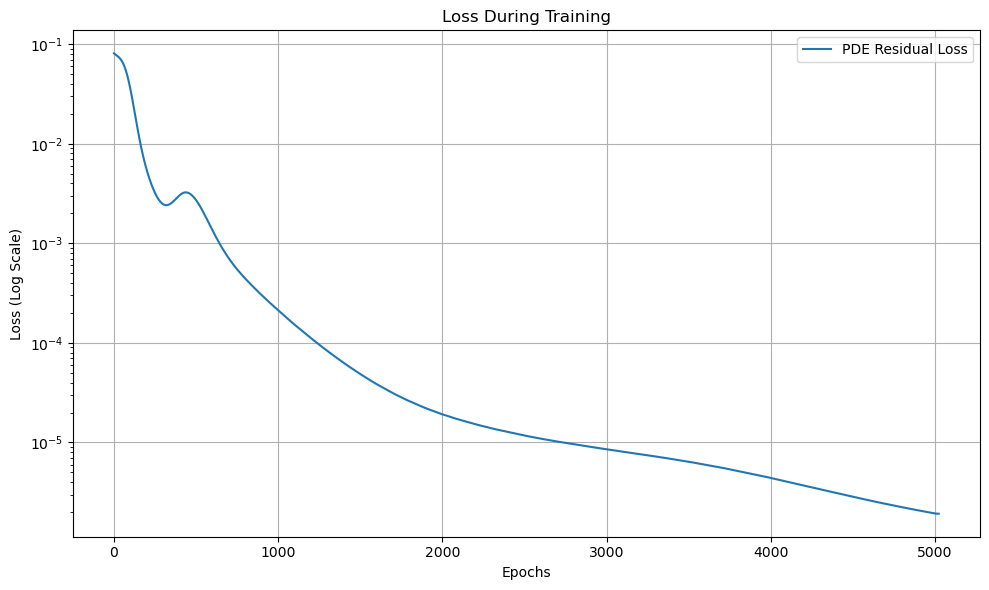

In [52]:
#limit, current
I_norm=10

# disctretization
batch_size_pde=2001
x_test,x_train= get_data(batch_size_pde)
x_num=x_train['pde'].cpu().detach().numpy()
wake=np.atleast_2d(bbr(x_num,1))
wake[x_num>0]=0#causulity
wake_tensor = torch.from_numpy(wake).float().to(device)


model = PINN(
    input_dim=1, 
    output_dim=1, 
    hidden_dim=100, 
    num_hidden=4,
).to(device)

t1 = default_timer()

train_pinn_adam(model, x_train, epochs=5000, lr=1e-4)

train_pinn_lbfgs(model, x_train, max_iter=1000, lr=0.01)

t2 = default_timer()
print(f"time cost：{t2 - t1} s")

plot_loss_history(model)

In [53]:
data_ref =pickle.load(open(r"D:\dis_pp\bbr_7_1000_1_10",'rb'))
xtt=np.linspace(-7,7,np.shape(data0)[0])
func_CS=CS(xtt,data0.T[0])


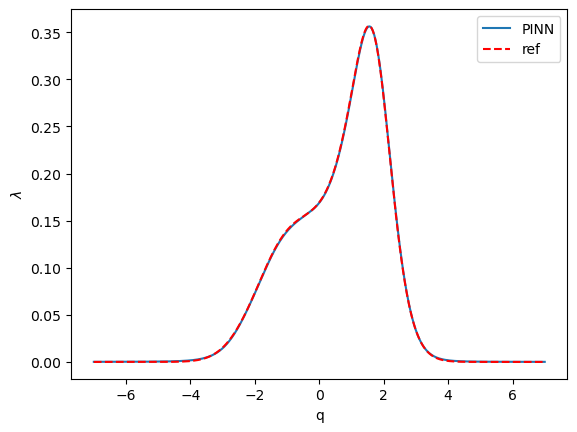

In [54]:
# ## **6. 结果评估与可视化**
u_pred = model(x_test).cpu().detach().numpy()
x0=x_test.cpu().detach().numpy()
plt.plot(x0,u_pred,label='PINN')
#plt.plot(x0[100:240],u_pred[100:240],label='Haissinski')

#plt.plot(x0,np.exp(-x0**2/2)/np.sqrt(2*np.pi),linestyle='dashed',label='gaussian')
plt.xlabel('q')
plt.ylabel(r'$\lambda$')
plt.plot(xtt,data0,linestyle='dashed',label='ref',c='r')
plt.legend()

In [92]:
pickle.dump(u_pred, open(r'D:\dis_pp\bbr_7_1000_1_10_pinn', 'wb'))#保存python矩